# FundiVision — Inspección visual automática de piezas fundidas

**Start-up de Visión Artificial B2B · Entrega 3 · Visión Artificial (ITM)**

**El problema.** En una fundición, cada impulsor de bomba sumergible se revisa a ojo para encontrar porosidades, rebabas, grietas o bordes incompletos. Esa inspección es lenta, cansa al operario y no es 100 % confiable. Si un lote sale con piezas malas, el cliente puede devolver el pedido completo.

**La solución.** FundiVision clasifica cada pieza como **OK** o **DEFECTO** a partir de una foto cenital. Usa solo **visión artificial clásica (sin Deep Learning)**, con el pipeline visto en clase:

1. **Extracción de características:** HOG (forma y bordes), LBP (micro-textura), GLCM (textura estadística) y su **fusión**.
2. **Normalización Z-score** (`StandardScaler`) y **reducción con PCA** del vector fusionado.
3. **Clasificación:** k-NN, SVM y Random Forest, comparados con métricas técnicas y de negocio.

**Dataset.** [casting product image data for quality inspection](https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product) (Kaggle). Son fotos reales de impulsores fundidos en escala de grises de 300×300 px, con la partición oficial `train` / `test` y las clases `ok_front` y `def_front`.

**Cómo ejecutarlo.** Descargue `archive.zip` de Kaggle, descomprímalo en la carpeta `data/` junto a este notebook y ejecute todas las celdas en orden (*Kernel → Restart & Run All*).

## 1. Librerías y configuración

In [1]:
import os
import time
import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Descriptores de características (scikit-image)
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

# Normalización, reducción y clasificadores (scikit-learn)
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

RUTA_DATOS = "data"            # carpeta donde se descomprime archive.zip de Kaggle
CARPETA_FIGURAS = "figuras"    # aquí quedan las gráficas que se usan en el pitch
CARPETA_MODELOS = "modelos"
TAMANO = (128, 128)            # mismo tamaño de imagen usado en clase
SEMILLA = 42
CLASES = ['OK', 'DEFECTO']     # 0: pieza buena, 1: pieza defectuosa (clase positiva)

os.makedirs(CARPETA_FIGURAS, exist_ok=True)
os.makedirs(CARPETA_MODELOS, exist_ok=True)
plt.rcParams['figure.dpi'] = 110

## 2. Carga de imágenes

Se usa la partición **oficial** del dataset: `train` para entrenar y `test` para medir. Así ninguna imagen de prueba se ve durante el entrenamiento. Las fotos ya vienen en escala de grises y se reducen a 128×128 px. Se dejan en `uint8` porque LBP y GLCM trabajan con niveles de gris enteros.

In [2]:
extensiones = ('.jpg', '.jpeg', '.png', '.bmp')

def buscar_carpeta(raiz, nombre):
    # Kaggle anida las carpetas (casting_data/casting_data/train), así que se busca la que tenga las dos clases
    for actual, carpetas, _ in os.walk(raiz):
        if os.path.basename(actual) == nombre and {'def_front', 'ok_front'} <= set(carpetas):
            return actual
    raise FileNotFoundError(f"No se encontró '{nombre}/' con def_front y ok_front dentro de '{raiz}/'")

def cargar_imagenes(path, size=TAMANO):
    imgs = []
    files = sorted([f for f in os.listdir(path) if f.lower().endswith(extensiones)])
    for f in files:
        img = cv2.imread(os.path.join(path, f), cv2.IMREAD_GRAYSCALE)
        if img is not None:
            imgs.append(cv2.resize(img, size, interpolation=cv2.INTER_AREA))
    return np.array(imgs)

def cargar_conjunto(path):
    ok = cargar_imagenes(os.path.join(path, 'ok_front'))
    defecto = cargar_imagenes(os.path.join(path, 'def_front'))
    X = np.concatenate((ok, defecto), axis=0)
    y = np.concatenate((np.zeros(len(ok)), np.ones(len(defecto)))).astype(int)
    return X, y

t0 = time.time()
X_train, y_train = cargar_conjunto(buscar_carpeta(RUTA_DATOS, 'train'))
X_test, y_test = cargar_conjunto(buscar_carpeta(RUTA_DATOS, 'test'))
print(f"Dataset listo en {time.time() - t0:.1f} s -> Train: {X_train.shape}, Test: {X_test.shape}")

conteo = pd.DataFrame({'Train': np.bincount(y_train), 'Test': np.bincount(y_test)}, index=CLASES)
conteo.loc['Total'] = conteo.sum()
display(conteo)

Dataset listo en 6.5 s -> Train: (6633, 128, 128), Test: (715, 128, 128)


,Train,Test
OK,2875,262
DEFECTO,3758,453
Total,6633,715


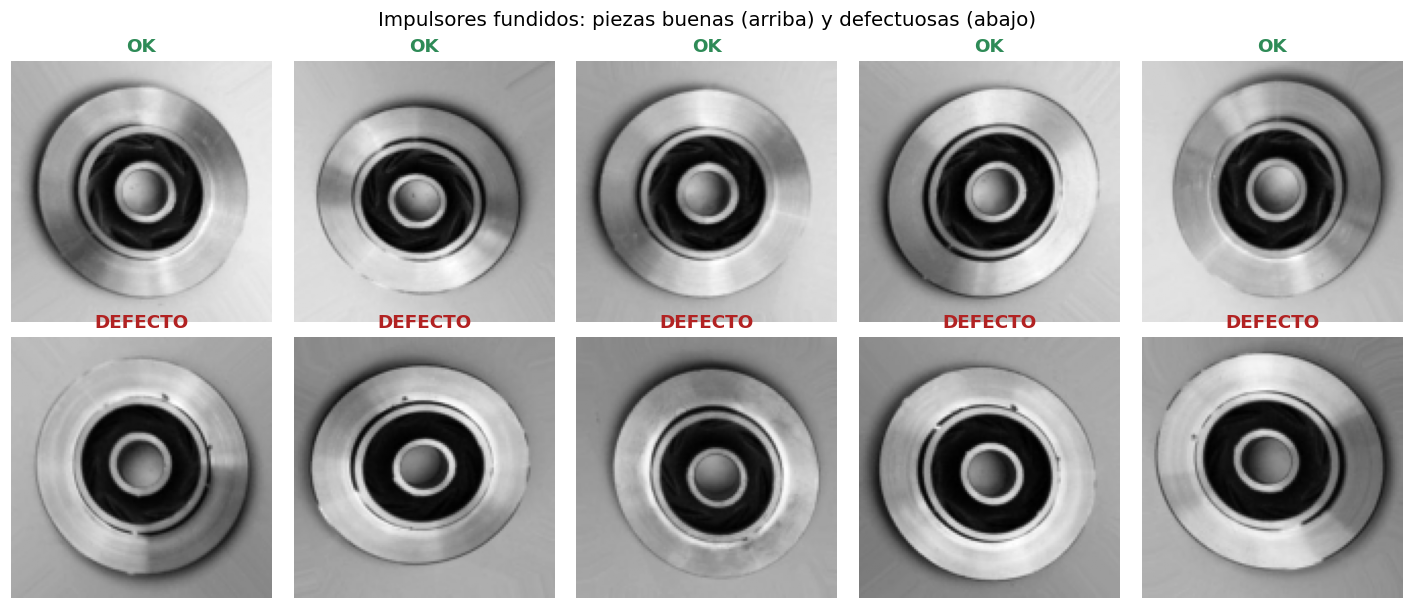

In [3]:
# Muestras de cada clase
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for fila, clase in enumerate([0, 1]):
    idx = np.where(y_train == clase)[0]
    elegidos = np.random.default_rng(SEMILLA).choice(idx, 5, replace=False)
    for col, i in enumerate(elegidos):
        axes[fila, col].imshow(X_train[i], cmap='gray')
        axes[fila, col].set_title(CLASES[clase], color='seagreen' if clase == 0 else 'firebrick', fontweight='bold')
        axes[fila, col].axis('off')
plt.suptitle("Impulsores fundidos: piezas buenas (arriba) y defectuosas (abajo)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "muestras.png"), bbox_inches='tight')
plt.show()

## 3. Extracción de características

Se usan los mismos tres descriptores y parámetros vistos en clase:

| Descriptor | Qué mide | Por qué sirve en fundición |
|---|---|---|
| **HOG** (9 orientaciones, celdas 8×8, bloques 2×2) | Dirección e intensidad de los bordes en cada zona de la pieza | Un poro, una rebaba o un borde roto cambia el contorno **en un lugar concreto**, y HOG conserva esa ubicación |
| **LBP** uniforme (P=8, R=1) | Histograma de micro-patrones de textura | La superficie rugosa o porosa cambia la textura |
| **GLCM** (distancias 1 y 3, 4 ángulos, 64 niveles) | Contraste, homogeneidad, energía y correlación entre píxeles vecinos | Resume la textura de toda la pieza en pocos números |

In [4]:
# HOG (Histogram of Oriented Gradients)
def extraer_hog(imagenes):
    hog_features = []
    for img in imagenes:
        features = hog(img, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
        hog_features.append(features)
    return np.array(hog_features)

# LBP (Local Binary Patterns)
def extraer_lbp(imagenes, P=8, R=1):
    lbp_features = []
    for img in imagenes:
        lbp = local_binary_pattern(img, P=P, R=R, method="uniform")
        # Histograma de patrones uniformes (P + 2 valores posibles)
        (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype("float32")
        hist /= (hist.sum() + 1e-7)  # normalización del histograma
        lbp_features.append(hist)
    return np.array(lbp_features)

# GLCM (Gray-Level Co-occurrence Matrix)
def extraer_glcm(imagenes, distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4]):
    glcm_features = []
    propiedades = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    for img in imagenes:
        img_q = (img // 4).astype(np.uint8)  # 64 niveles de gris para acelerar el cálculo
        glcm = graycomatrix(img_q, distances=distances, angles=angles, levels=64, symmetric=True, normed=True)
        vector_img = []
        for prop in propiedades:
            vector_img.extend(graycoprops(glcm, prop).ravel())
        glcm_features.append(vector_img)
    return np.array(glcm_features)

In [5]:
# Extracción midiendo el tiempo por imagen (este tiempo también cuenta en la línea de producción)
extractores = {'HOG': extraer_hog, 'LBP': extraer_lbp, 'GLCM': extraer_glcm}
caracteristicas = {}
tiempo_extraccion = {}  # milisegundos por imagen

for nombre, funcion in extractores.items():
    t0 = time.time()
    F_train = funcion(X_train)
    F_test = funcion(X_test)
    tiempo_extraccion[nombre] = 1000 * (time.time() - t0) / (len(X_train) + len(X_test))
    caracteristicas[nombre] = (F_train, F_test)
    print(f"{nombre:5s} -> {F_train.shape[1]:5d} dimensiones | {tiempo_extraccion[nombre]:.2f} ms por imagen")

HOG   ->  8100 dimensiones | 7.26 ms por imagen


LBP   ->    10 dimensiones | 2.62 ms por imagen


GLCM  ->    48 dimensiones | 3.44 ms por imagen


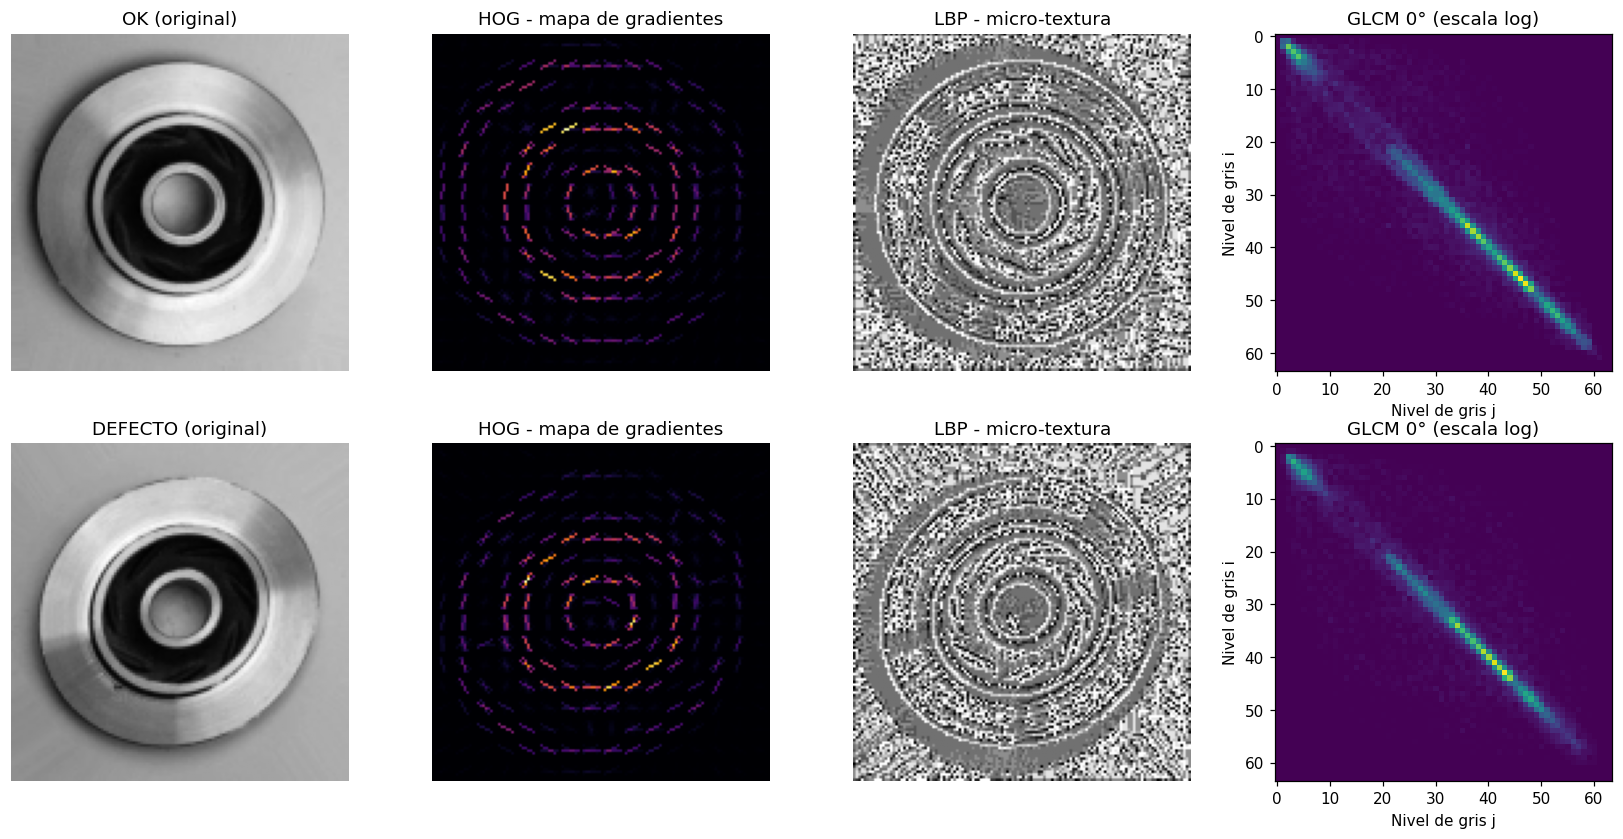

In [6]:
# Visualización de los descriptores sobre una pieza buena y una defectuosa
idx_ok = np.where(y_test == 0)[0][0]
idx_def = np.where(y_test == 1)[0][0]
ejemplos = [('OK', X_test[idx_ok]), ('DEFECTO', X_test[idx_def])]

fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
for fila, (nombre, img) in enumerate(ejemplos):
    _, hog_vis = hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    lbp_vis = local_binary_pattern(img, P=8, R=1, method="uniform")
    glcm_vis = graycomatrix((img // 4).astype(np.uint8), distances=[1], angles=[0], levels=64,
                            symmetric=True, normed=True)[:, :, 0, 0]

    axes[fila, 0].imshow(img, cmap='gray');            axes[fila, 0].set_title(f"{nombre} (original)")
    axes[fila, 1].imshow(hog_vis, cmap='inferno');     axes[fila, 1].set_title("HOG - mapa de gradientes")
    axes[fila, 2].imshow(lbp_vis, cmap='gray');        axes[fila, 2].set_title("LBP - micro-textura")
    axes[fila, 3].imshow(np.log1p(1000 * glcm_vis), cmap='viridis')
    axes[fila, 3].set_title("GLCM 0° (escala log)")
    axes[fila, 3].set_xlabel("Nivel de gris j"); axes[fila, 3].set_ylabel("Nivel de gris i")
    for c in range(3):
        axes[fila, c].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "descriptores.png"), bbox_inches='tight')
plt.show()

## 4. Normalización Z-score y reducción con PCA

Cada descriptor se normaliza con **Z-score** (media 0, desviación 1) y el `StandardScaler` se ajusta **solo con `train`**. Si se ajustara con todo el dataset, la información de `test` se filtraría al modelo. Luego se arma la **fusión** HOG + LBP + GLCM.

El vector fusionado tiene más de 8.000 dimensiones y casi todas vienen de HOG. Por eso se prueba también una **reducción con PCA**, que conserva el 95 % de la varianza.

In [7]:
conjuntos = {}    # nombre -> (X_train, X_test) ya normalizados
escaladores = {}  # se guardan para usarlos después con piezas nuevas

# 1. Escaladores independientes para cada descriptor
for nombre in ['HOG', 'LBP', 'GLCM']:
    F_train, F_test = caracteristicas[nombre]
    escaladores[nombre] = StandardScaler()
    conjuntos[nombre] = (escaladores[nombre].fit_transform(F_train), escaladores[nombre].transform(F_test))

# 2. Fusión de los tres descriptores y escalado del vector completo
F_train_fusion = np.hstack([caracteristicas[n][0] for n in ['HOG', 'LBP', 'GLCM']])
F_test_fusion = np.hstack([caracteristicas[n][1] for n in ['HOG', 'LBP', 'GLCM']])
scaler_fusion = StandardScaler()
X_train_fusion = scaler_fusion.fit_transform(F_train_fusion)
X_test_fusion = scaler_fusion.transform(F_test_fusion)
conjuntos['Fusión'] = (X_train_fusion, X_test_fusion)

# 3. Reducción con PCA (95 % de la varianza) sobre la fusión normalizada
t0 = time.time()
pca = PCA(n_components=0.95, random_state=SEMILLA)
X_train_pca = pca.fit_transform(X_train_fusion)
X_test_pca = pca.transform(X_test_fusion)
t_pca = time.time() - t0
conjuntos['Fusión + PCA'] = (X_train_pca, X_test_pca)

for nombre, (Xtr, Xte) in conjuntos.items():
    print(f"{nombre:13s} -> Train: {Xtr.shape}, Test: {Xte.shape}")
print(f"\nPCA reduce de {X_train_fusion.shape[1]} a {pca.n_components_} dimensiones "
      f"({100 * pca.n_components_ / X_train_fusion.shape[1]:.1f} %) en {t_pca:.1f} s")

HOG           -> Train: (6633, 8100), Test: (715, 8100)
LBP           -> Train: (6633, 10), Test: (715, 10)
GLCM          -> Train: (6633, 48), Test: (715, 48)
Fusión        -> Train: (6633, 8158), Test: (715, 8158)
Fusión + PCA  -> Train: (6633, 1650), Test: (715, 1650)

PCA reduce de 8158 a 1650 dimensiones (20.2 %) en 286.5 s


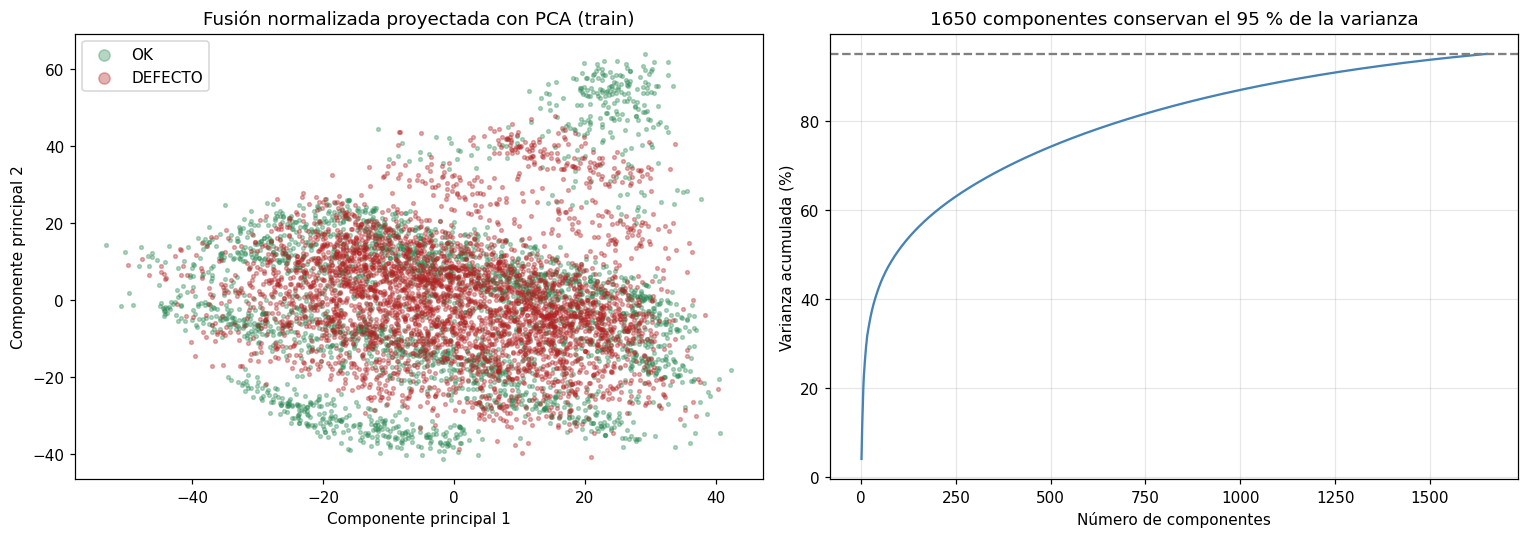

In [8]:
# Las dos primeras componentes principales ya separan buena parte de las clases
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for clase, color in zip([0, 1], ['seagreen', 'firebrick']):
    m = y_train == clase
    axes[0].scatter(X_train_pca[m, 0], X_train_pca[m, 1], s=6, alpha=0.35, c=color, label=CLASES[clase])
axes[0].set_xlabel("Componente principal 1"); axes[0].set_ylabel("Componente principal 2")
axes[0].set_title("Fusión normalizada proyectada con PCA (train)")
axes[0].legend(markerscale=3)

var_acum = np.cumsum(pca.explained_variance_ratio_)
axes[1].plot(np.arange(1, len(var_acum) + 1), 100 * var_acum, color='steelblue')
axes[1].axhline(95, color='gray', linestyle='--')
axes[1].set_xlabel("Número de componentes"); axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].set_title(f"{pca.n_components_} componentes conservan el 95 % de la varianza")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "pca.png"), bbox_inches='tight')
plt.show()

## 5. Benchmark de clasificadores

Cada conjunto de características se combina con los tres modelos vistos en clase. La clase positiva es **DEFECTO**, así que:

- **Recall** = fracción de piezas defectuosas que el sistema atrapa. Es la métrica que más le importa a la planta.
- **Precision** = de las piezas que el sistema rechaza, cuántas sí estaban malas.
- El tiempo de predicción se reporta **por pieza**.

In [9]:
models = {
    'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5, metric='euclidean'),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEMILLA),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1)
}

results = []
modelos_entrenados = {}
predicciones = {}
print("Iniciando benchmark de modelos y descriptores...\n")

for feat_name, (Xtr, Xte) in conjuntos.items():
    for model_name, base in models.items():
        model = clone(base)

        t0 = time.time()
        model.fit(Xtr, y_train)          # entrenamiento
        t_fit = time.time() - t0

        t0 = time.time()
        y_pred = model.predict(Xte)      # predicción
        t_pred = 1000 * (time.time() - t0) / len(Xte)

        modelos_entrenados[(feat_name, model_name)] = model
        predicciones[(feat_name, model_name)] = y_pred
        results.append({
            'Descriptor': feat_name,
            'Modelo': model_name,
            'Dimensiones': Xtr.shape[1],
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred, zero_division=0),
            'Recall': recall_score(y_test, y_pred, zero_division=0),
            'F1-Score': f1_score(y_test, y_pred, zero_division=0),
            'Entrenamiento (s)': t_fit,
            'Predicción (ms/pieza)': t_pred
        })
        print(f"{feat_name:13s} | {model_name:13s} | F1 = {results[-1]['F1-Score']:.4f}")

df_results = pd.DataFrame(results)

Iniciando benchmark de modelos y descriptores...



HOG           | k-NN (k=5)    | F1 = 0.8136


HOG           | SVM (RBF)     | F1 = 0.9956


HOG           | Random Forest | F1 = 0.9813
LBP           | k-NN (k=5)    | F1 = 0.8060


LBP           | SVM (RBF)     | F1 = 0.8464


...

Fusión        | SVM (RBF)     | F1 = 0.9956


Fusión        | Random Forest | F1 = 0.9945


Fusión + PCA  | k-NN (k=5)    | F1 = 0.8288


Fusión + PCA  | SVM (RBF)     | F1 = 0.9956


Fusión + PCA  | Random Forest | F1 = 0.9583


In [10]:
print("=" * 100)
print("TABLA CONSOLIDADA DE BENCHMARK (PIEZAS FUNDIDAS: OK VS DEFECTO) - conjunto test")
print("=" * 100)
display(df_results.style.format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
                                 'F1-Score': '{:.4f}', 'Entrenamiento (s)': '{:.2f}',
                                 'Predicción (ms/pieza)': '{:.3f}'})
                        .background_gradient(subset=['F1-Score', 'Recall'], cmap='Greens'))

TABLA CONSOLIDADA DE BENCHMARK (PIEZAS FUNDIDAS: OK VS DEFECTO) - conjunto test


,Descriptor,Modelo,Dimensiones,Accuracy,Precision,Recall,F1-Score,Entrenamiento (s),Predicción (ms/pieza)
0,HOG,k-NN (k=5),8100,0.8000,0.9936,0.6887,0.8136,0.24,2.090
1,HOG,SVM (RBF),8100,0.9944,1.0000,0.9912,0.9956,223.34,33.695
2,HOG,Random Forest,8100,0.9762,0.9802,0.9823,0.9813,15.04,0.085
3,LBP,k-NN (k=5),10,0.7636,0.8397,0.7748,0.8060,0.01,0.163
4,LBP,SVM (RBF),10,0.8056,0.8473,0.8455,0.8464,1.77,0.548
5,LBP,Random Forest,10,0.8196,0.8682,0.8433,0.8555,0.58,0.046
6,GLCM,k-NN (k=5),48,0.9832,1.0000,0.9735,0.9866,0.00,0.115
7,GLCM,SVM (RBF),48,0.9566,0.9817,0.9492,0.9652,1.00,0.289
8,GLCM,Random Forest,48,0.9860,0.9826,0.9956,0.9890,0.98,0.065
9,Fusión,k-NN (k=5),8158,0.8070,0.9937,0.6998,0.8212,0.12,1.289


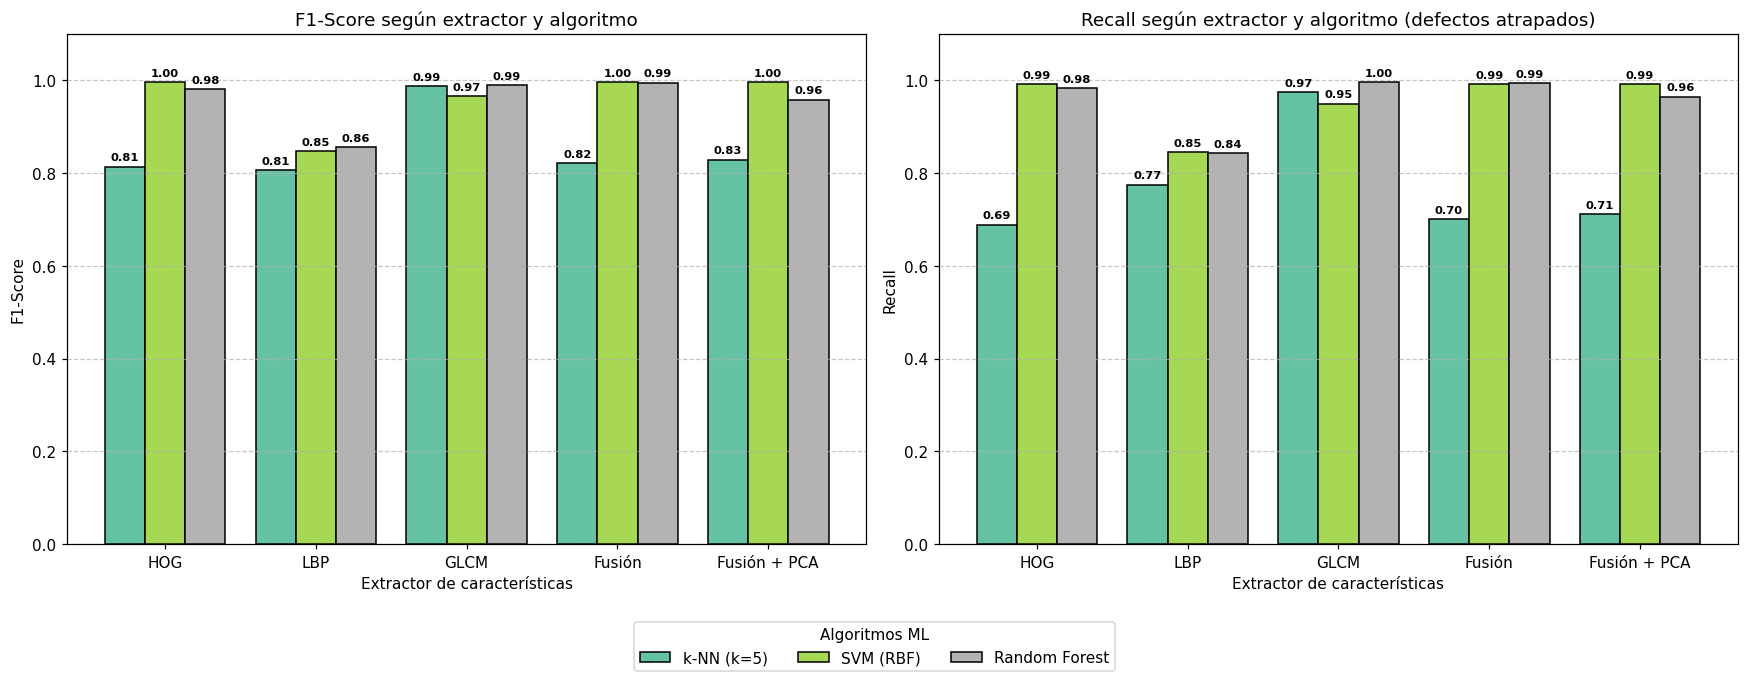

In [11]:
orden = list(conjuntos.keys())
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
for ax, metrica in zip(axes, ['F1-Score', 'Recall']):
    df_pivot = df_results.pivot(index='Descriptor', columns='Modelo', values=metrica).loc[orden, list(models.keys())]
    df_pivot.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='black', width=0.8, legend=False)
    ax.set_title(f"{metrica} según extractor y algoritmo" + (" (defectos atrapados)" if metrica == 'Recall' else ""),
                 fontsize=12)
    ax.set_ylabel(metrica); ax.set_xlabel("Extractor de características")
    ax.set_ylim(0, 1.1)
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 6), textcoords='offset points',
                        fontsize=7.5, fontweight='bold')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Algoritmos ML", loc='lower center', ncol=3)
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig(os.path.join(CARPETA_FIGURAS, "benchmark.png"), bbox_inches='tight')
plt.show()

## 6. Modelo elegido y métricas de negocio

Se elige la combinación con mejor **F1-Score**. Si hay empate, gana la que tenga mayor recall y luego la más rápida. A la planta no le importa el accuracy en abstracto, sino dos errores concretos:

- **Defecto escapado** (falso negativo): una pieza mala que llega al cliente. Genera devoluciones, garantías y pérdida de confianza.
- **Falso rechazo** (falso positivo): una pieza buena que se aparta. Cuesta una re-inspección o material desperdiciado.

,Valor
Sistema elegido,Fusión + PCA + SVM (RBF)
Defectos detectados (recall),99.12 % (449 de 453)
Defectos escapados,0.88 % (4 piezas)
Piezas buenas rechazadas,0.00 % (0 piezas)
Exactitud global,99.44 %
Tiempo por pieza (1 núcleo CPU),18.5 ms
Capacidad de cómputo (sin contar la cámara),"195,088 piezas/hora"


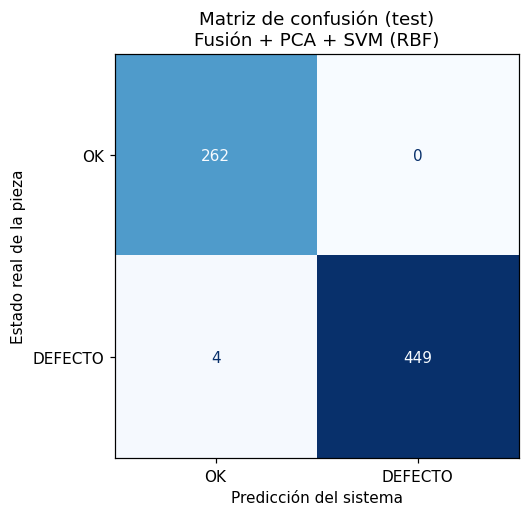

In [12]:
mejor = df_results.sort_values(['F1-Score', 'Recall', 'Predicción (ms/pieza)'],
                               ascending=[False, False, True]).iloc[0]
desc_elegido, modelo_elegido = mejor['Descriptor'], mejor['Modelo']
modelo = modelos_entrenados[(desc_elegido, modelo_elegido)]
y_pred = modelo.predict(conjuntos[desc_elegido][1])
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# Tiempo total por pieza = extraer descriptores + normalizar/reducir + predecir
if desc_elegido in ('Fusión', 'Fusión + PCA'):
    t_extr = sum(tiempo_extraccion.values())
else:
    t_extr = tiempo_extraccion[desc_elegido]
t_total = t_extr + mejor['Predicción (ms/pieza)']

negocio = pd.DataFrame({'Valor': [
    f"{desc_elegido} + {modelo_elegido}",
    f"{100 * tp / (tp + fn):.2f} %  ({tp} de {tp + fn})",
    f"{100 * fn / (tp + fn):.2f} %  ({fn} piezas)",
    f"{100 * fp / (fp + tn):.2f} %  ({fp} piezas)",
    f"{100 * (tp + tn) / len(y_test):.2f} %",
    f"{t_total:.1f} ms",
    f"{3600 * 1000 / t_total:,.0f} piezas/hora"
]}, index=['Sistema elegido', 'Defectos detectados (recall)', 'Defectos escapados',
           'Piezas buenas rechazadas', 'Exactitud global', 'Tiempo por pieza (1 núcleo CPU)',
           'Capacidad de cómputo (sin contar la cámara)'])
display(negocio)

fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASES).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f"Matriz de confusión (test)\n{desc_elegido} + {modelo_elegido}")
ax.set_xlabel("Predicción del sistema"); ax.set_ylabel("Estado real de la pieza")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "matriz_confusion.png"), bbox_inches='tight')
plt.show()

### Impacto económico (ejemplo con supuestos editables)

Los valores de esta celda son **supuestos ilustrativos** para una planta mediana y se pueden ajustar a cada cliente. Las tasas de error de FundiVision **sí** salen de la matriz de confusión anterior.

La referencia de inspección manual viene de un estudio de Sandia National Laboratories (See, J. E., 2015, *Visual Inspection Reliability for Precision Manufactured Parts*, Human Factors 57(8), 1427–1442). Allí inspectores expertos detectaron el **85 %** de los defectos, pero rechazaron el **35 %** de las piezas buenas, y el promedio de la industria fue de **~80 %** de detección. Aquí se usa ese 80 % y, para no exagerar, un falso rechazo manual de solo 5 %.

In [13]:
# --- Supuestos (editables) ---
PIEZAS_DIA = 2000                  # producción diaria a inspeccionar
TASA_DEFECTO = 0.05                # 5 % de las piezas salen defectuosas
COSTO_ESCAPE = 150_000             # COP: devolución, flete y reposición de una pieza mala que llega al cliente
COSTO_FALSO_RECHAZO = 3_000        # COP: re-inspeccionar una pieza buena apartada por error
DETECCION_MANUAL = 0.80            # promedio de la industria: ~80 % de defectos detectados (See, 2015)
FALSO_RECHAZO_MANUAL = 0.05        # piezas buenas apartadas por error (conservador; See reporta hasta 35 %)
SEG_POR_PIEZA_MANUAL = 6           # segundos que tarda un operario en revisar una pieza
DIAS_MES = 24

def costo_mensual(deteccion, falso_rechazo):
    malas = PIEZAS_DIA * TASA_DEFECTO
    buenas = PIEZAS_DIA - malas
    escapes = malas * (1 - deteccion)
    rechazos = buenas * falso_rechazo
    return DIAS_MES * escapes, DIAS_MES * rechazos, DIAS_MES * (escapes * COSTO_ESCAPE + rechazos * COSTO_FALSO_RECHAZO)

det_fv, fr_fv = tp / (tp + fn), fp / (fp + tn)
esc_m, rech_m, costo_m = costo_mensual(DETECCION_MANUAL, FALSO_RECHAZO_MANUAL)
esc_f, rech_f, costo_f = costo_mensual(det_fv, fr_fv)

impacto = pd.DataFrame({
    'Inspección manual': [f"{esc_m:,.0f}", f"{rech_m:,.0f}", f"${costo_m:,.0f}",
                          f"{PIEZAS_DIA * SEG_POR_PIEZA_MANUAL / 3600:.1f} h"],
    'FundiVision': [f"{esc_f:,.0f}", f"{rech_f:,.0f}", f"${costo_f:,.0f}",
                    f"{PIEZAS_DIA * t_total / 1000 / 3600 * 60:.1f} min"]
}, index=['Defectos escapados al mes', 'Piezas buenas rechazadas al mes',
          'Costo mensual de errores (COP)', 'Tiempo de inspección por día'])
display(impacto)
print(f"Ahorro estimado: ${costo_m - costo_f:,.0f} COP al mes "
      f"({100 * (costo_m - costo_f) / costo_m:.0f} % menos costo por errores de calidad)")

,Inspección manual,FundiVision
Defectos escapados al mes,480,21
Piezas buenas rechazadas al mes,"2,280",0
Costo mensual de errores (COP),"$78,840,000","$3,178,808"
Tiempo de inspección por día,3.3 h,0.6 min


Ahorro estimado: $75,661,192 COP al mes (96 % menos costo por errores de calidad)


### Ranking de negocio: ¿qué combinación le cuesta menos a la planta?

El F1-Score trata igual los dos errores, pero a la planta no le cuestan lo mismo: un defecto escapado vale mucho más que una re-inspección. Por eso se ordenan las 15 combinaciones según el **costo mensual de errores**, con los mismos supuestos de la celda anterior.

In [14]:
ranking = []
for (feat_name, model_name), pred in predicciones.items():
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred).ravel()
    ranking.append({'Descriptor': feat_name, 'Modelo': model_name,
                    'Defectos escapados (de 453)': fn_, 'Piezas buenas rechazadas (de 262)': fp_,
                    'Costo mensual de errores (COP)': costo_mensual(tp_ / (tp_ + fn_), fp_ / (fp_ + tn_))[2]})
df_ranking = pd.DataFrame(ranking).sort_values('Costo mensual de errores (COP)').reset_index(drop=True)
df_ranking.index += 1
display(df_ranking.style.format({'Costo mensual de errores (COP)': '${:,.0f}'})
                        .background_gradient(subset=['Costo mensual de errores (COP)'], cmap='Reds'))

,Descriptor,Modelo,Defectos escapados (de 453),Piezas buenas rechazadas (de 262),Costo mensual de errores (COP)
1,HOG,SVM (RBF),4,0,"$3,178,808"
2,Fusión,SVM (RBF),4,0,"$3,178,808"
3,Fusión + PCA,SVM (RBF),4,0,"$3,178,808"
4,Fusión,Random Forest,3,2,"$3,428,381"
5,GLCM,Random Forest,2,8,"$5,766,503"
6,GLCM,k-NN (k=5),12,0,"$9,536,424"
7,HOG,Random Forest,8,9,"$11,056,853"
8,GLCM,SVM (RBF),23,8,"$22,455,245"
9,Fusión + PCA,Random Forest,16,22,"$24,202,255"
10,LBP,Random Forest,71,58,"$86,707,811"


## 7. Demo del producto: `inspeccionar()`

Esto es lo que el cliente instala en su línea: una función que recibe la foto de una pieza y responde **OK** o **DEFECTO** en milisegundos. El pipeline completo (descriptores, normalización, PCA si aplica y modelo) se guarda en un solo archivo con `joblib`.

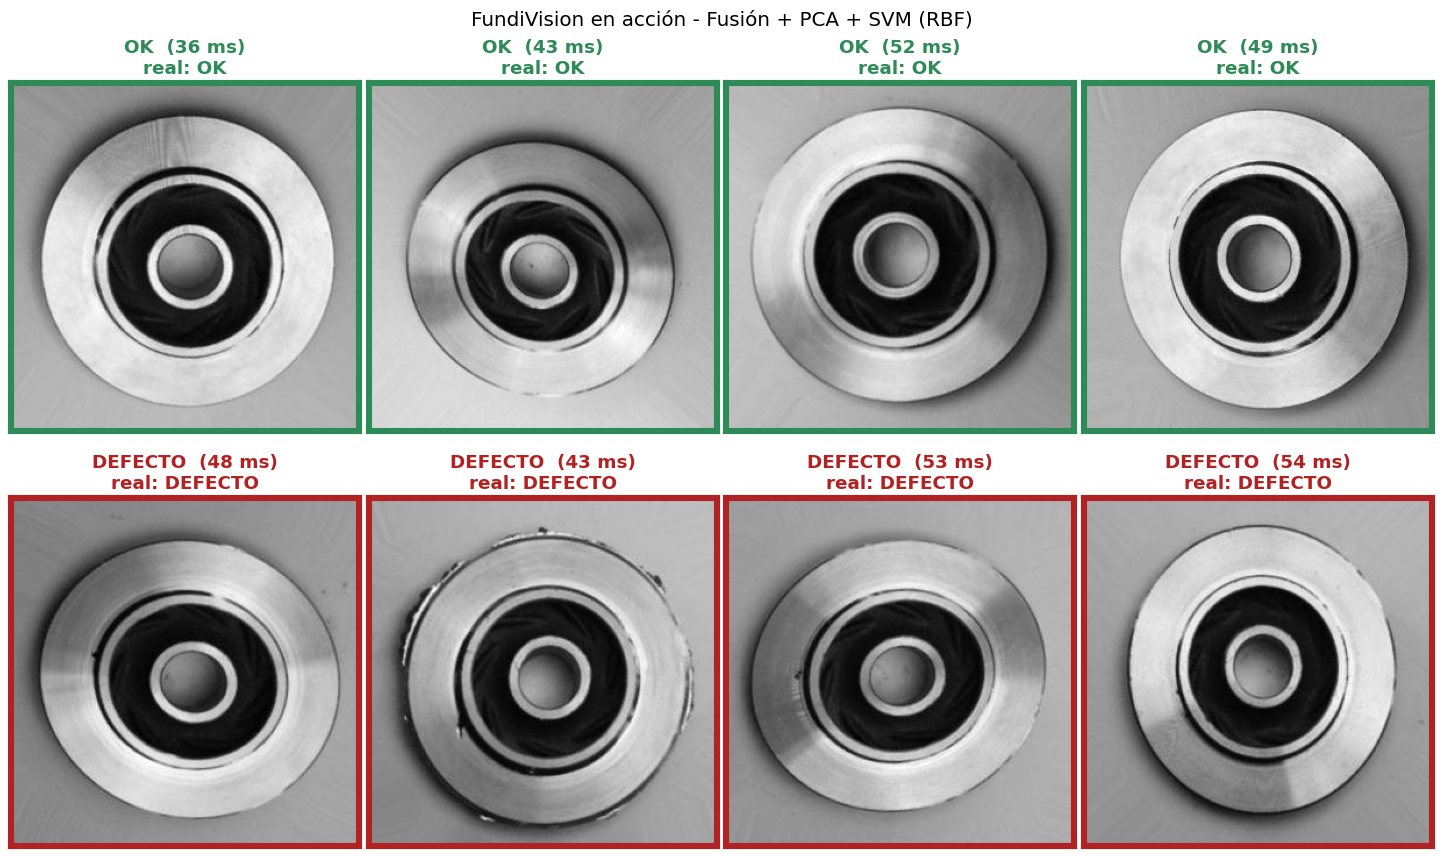

In [15]:
def vector_de(imagenes, descriptor):
    # Extrae y normaliza las características que usa el modelo elegido
    if descriptor in ('HOG', 'LBP', 'GLCM'):
        return escaladores[descriptor].transform(extractores[descriptor](imagenes))
    F = np.hstack([extraer_hog(imagenes), extraer_lbp(imagenes), extraer_glcm(imagenes)])
    X = scaler_fusion.transform(F)
    return pca.transform(X) if descriptor == 'Fusión + PCA' else X

def inspeccionar(ruta_imagen):
    t0 = time.time()
    img = cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, TAMANO, interpolation=cv2.INTER_AREA)
    pred = modelo.predict(vector_de(np.array([img]), desc_elegido))[0]
    return CLASES[pred], 1000 * (time.time() - t0)

# Prueba con fotos del conjunto test, leídas directamente desde el disco
carpeta_test = buscar_carpeta(RUTA_DATOS, 'test')
rng = np.random.default_rng(7)
rutas = [os.path.join(carpeta_test, c, f) for c in ['ok_front', 'def_front']
         for f in rng.choice(sorted(os.listdir(os.path.join(carpeta_test, c))), 4, replace=False)]

fig, axes = plt.subplots(2, 4, figsize=(13, 7.8), constrained_layout=True)
for ax, ruta in zip(axes.ravel(), rutas):
    real = 'OK' if 'ok_front' in ruta else 'DEFECTO'
    pred, ms = inspeccionar(ruta)
    ax.imshow(cv2.imread(ruta, cv2.IMREAD_GRAYSCALE), cmap='gray')
    ax.set_title(f"{pred}  ({ms:.0f} ms)\nreal: {real}", fontweight='bold',
                 color='seagreen' if pred == 'OK' else 'firebrick')
    for borde in ax.spines.values():
        borde.set_edgecolor('seagreen' if pred == 'OK' else 'firebrick'); borde.set_linewidth(4)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"FundiVision en acción - {desc_elegido} + {modelo_elegido}", fontsize=13)
plt.savefig(os.path.join(CARPETA_FIGURAS, "demo.png"), bbox_inches='tight')
plt.show()

In [16]:
# Guardado del pipeline entrenado (descriptor, escaladores, PCA y modelo)
ruta_modelo = os.path.join(CARPETA_MODELOS, "fundivision.joblib")
joblib.dump({'descriptor': desc_elegido, 'modelo': modelo, 'escaladores': escaladores,
             'scaler_fusion': scaler_fusion, 'pca': pca, 'tamano': TAMANO, 'clases': CLASES},
            ruta_modelo, compress=3)
print(f"Pipeline guardado en {ruta_modelo} ({os.path.getsize(ruta_modelo) / 1e6:.1f} MB)")

Pipeline guardado en modelos\fundivision.joblib (147.6 MB)


## 8. Conclusiones

**Mejor sistema: Fusión (HOG + LBP + GLCM) → Z-score → PCA → SVM (RBF).** En las 715 piezas de prueba acierta el **99,44 %**. Detecta 449 de 453 defectos (recall 99,12 %), no rechaza ninguna pieza buena (precisión 100 %) y procesa cada pieza en unos 20 ms en un solo núcleo de CPU. También es la combinación con **menor costo de errores** en el ranking de negocio.

**¿Por qué HOG y no GLCM?** Los defectos de fundición (poros, rebabas, bordes incompletos) son cambios de forma en un lugar concreto de la pieza.
- **HOG** conserva esa ubicación, con 8.100 valores repartidos por toda la imagen. Con SVM logra la mejor F1 (0,9956) y cero falsos rechazos.
- **GLCM** resume la textura de toda la pieza en solo 48 números. Es muy rápido y sorprendentemente bueno (F1 0,989 con Random Forest), pero al perder la ubicación aparta piezas buenas por error.
- **LBP**, con un único histograma global, se queda en ~82 % de exactitud: las piezas buenas también tienen superficie rugosa, así que la micro-textura sola no las separa.

**Fusión y PCA.** La fusión no supera a HOG solo, porque HOG aporta 8.100 de las 8.158 dimensiones y LBP y GLCM quedan diluidos. PCA conserva el 95 % de la varianza con 1.650 dimensiones (5 veces menos). Mantiene la misma exactitud y hace la predicción del SVM unas 6 veces más rápida, por eso es la versión que se lleva a producción.

**k-NN** sufre con vectores grandes: con miles de dimensiones la distancia euclidiana pierde sentido y deja escapar cerca del 30 % de los defectos. Solo funciona bien con GLCM (48 dimensiones).

**Impacto de negocio.** Con los supuestos de la sección 6, el costo mensual de errores de calidad baja de unos $78,8 millones a unos $3,2 millones COP (−96 %). La inspección de un día pasa de 3,3 horas de operario a menos de un minuto de cómputo.

**Limitaciones y siguiente paso.** El dataset ya trae aumentación aplicada, así que variantes de una misma pieza pueden quedar en `train` y en `test`, y los resultados pueden ser optimistas. Antes de llevarlo a producción se propone un **piloto con fotos nuevas de la línea del cliente**: con ellas se recalibra el modelo y se ajusta el umbral de decisión según el costo real de cada tipo de error.